# CI08 — Prévision des exportations de services du Maroc
**BD & DS — ENCG Settat — S7 CI** · A. Larhlimi

Objectif : comparer Ridge à la persistance, à un trimestre, sur les huit derniers trimestres. Réussite si le RMSE de Ridge est au moins 10 % inférieur. Les recettes sont en millions USD courants. Une observation = un trimestre, Maroc vers le monde, total des services commerciaux (pas de code SH).

**Avant de lancer :** télécharger le CSV réel sur [WTO Stats](https://stats.wto.org/), rubrique International Trade Statistics → Trade in commercial services → Commercial services exports by main sector — quarterly (Million US dollar). Sélectionner Morocco, total Commercial services, toutes les périodes disponibles (idéalement 2005 à la dernière période publiée), monde si proposé. Cliquer Apply puis CSV. Dans Colab, lancer toutes les cellules ; la cellule de chargement demandera ce fichier. Ne pas utiliser de données annuelles, d'importations ni de secteurs séparés. Guide officiel : https://www.wto.org/english/res_e/statis_e/short_term_stats_e.htm.

Les graphiques exploratoires se fondent sur les données disponibles jusqu'à l'origine du premier test afin de ne pas consulter les cibles du test avant le réglage. Le graphique des niveaux sur la série complète est produit après évaluation. Le fichier LaTeX final est généré à partir du texte fourni ; les résultats ne sont jamais inventés.

In [9]:
from pathlib import Path
import re, sys, unicodedata, shutil, zipfile
from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit
import sklearn
np.random.seed(42)
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FIG = ROOT/'figures'; RAW = ROOT/'data'/'raw'; REP = ROOT/'rapport'
for d in (FIG, RAW, REP): d.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize':(9,4), 'axes.grid':True, 'grid.alpha':.22, 'font.size':11, 'axes.spines.top':False, 'axes.spines.right':False})
print('Python',sys.version.split()[0], '| pandas',pd.__version__, '| scikit-learn',sklearn.__version__)


Python 3.13.18 | pandas 2.2.3 | scikit-learn 1.6.1


## 1. Importer les données réelles
La cellule accepte un CSV OMC en format long (Year / Period / Value) ou un tableau large à colonnes trimestrielles. En dernier recours, utiliser un CSV à deux colonnes `date,export_services` transcrit de l'export OMC, sans changer les unités. La date d'extraction est à renseigner avec la date réelle de téléchargement ; si le fichier est téléchargé aujourd'hui, conserver la valeur proposée. Les métadonnées de diffusion doivent être vérifiées avant publication sur GitHub.

In [2]:
DATE_EXTRACTION = date.today().strftime('%d/%m/%Y') # Modifier si le CSV a été téléchargé auparavant
SOURCE = 'https://stats.wto.org/'
CHEMIN = RAW/'donnees_CI08.csv'
if not CHEMIN.exists():
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f'Déposer le CSV OMC dans {CHEMIN}')
    uploaded = files.upload()
    csvs = [(k,v) for k,v in uploaded.items() if k.lower().endswith('.csv')]
    if len(csvs)!=1: raise ValueError('Téléverser exactement un fichier CSV de l’OMC.')
    CHEMIN.write_bytes(csvs[0][1])
for encoding in ('utf-8-sig','cp1252'):
    try:
        raw = pd.read_csv(CHEMIN, sep=None, engine='python', encoding=encoding, dtype=str)
        break
    except UnicodeDecodeError: pass
print('Dimensions du CSV original :', raw.shape)
display(raw.head())

def norm(s):
    return re.sub(r'[^a-z0-9]','',unicodedata.normalize('NFKD',str(s)).encode('ascii','ignore').decode().lower())
cols = {norm(c):c for c in raw.columns}
def col(*names):
    return next((cols[norm(x)] for x in names if norm(x) in cols),None)
d = raw.copy()
# Contrôles des dimensions commerciales si présentes dans l'export.
for names, pattern in [
    (('Reporting Economy','ReportingEconomy','Reporter','Economy'),r'(?i)morocco|maroc|^504$|^MAR$'),
    (('Indicator','Indicator name'),r'(?i)(export|exportation).*(quarter|trimest)|(quarter|trimest).*(export|exportation)'),
    (('Product/Sector','ProductOrSector','Sector','Product or Sector'),r'(?i)^(?:.*?\s-\s)?(?:total\s+)?(?:commercial services(?:,? total)?|services commerciaux(?:,? total)?|total commercial services)$'),
    (('Partner Economy','PartnerEconomy','Partner'),r'(?i)world|monde|^000$|^WLD$'),
    (('Unit','Unit of measurement'),r'(?i)million.*(?:us|usd|dollar)|(?:us|usd|dollar).*million'),
]:
    c = col(*names)
    if c is None or d[c].isna().all(): continue
    mask = d[c].fillna('').str.strip().str.contains(pattern,regex=True)
    if not mask.any():
        raise ValueError(f'Vérifier le filtre {c} : {d[c].dropna().unique()[:10]}. Exporter uniquement le total des exportations trimestrielles du Maroc, millions USD.')
    d = d.loc[mask].copy()

def quarter(s, year=None):
    s=str(s).strip().upper()
    for word,digit in [('FIRST','1'),('SECOND','2'),('THIRD','3'),('FOURTH','4')]: s=s.replace(word+' QUARTER','Q'+digit)
    s=re.sub(r'([1-4])(?:ST|ND|RD|TH)\s+QUARTER',r'Q\1',s)
    y=re.search(r'\b(19\d{2}|20\d{2})\b',s)
    if not y: y=re.search(r'(19\d{2}|20\d{2})',s)
    q=re.search(r'(?:Q|T|QUARTER\s*|TRIMESTRE\s*)\s*([1-4])',s)
    if not q: q=re.search(r'([1-4])\s*(?:Q|T)\b',s)
    yy=int(y.group(1)) if y else (int(float(year)) if year is not None and pd.notna(year) else None)
    if not q and yy is not None and re.fullmatch(r'[1-4]',s): return pd.Period(f'{yy}Q{s}',freq='Q')
    if q and yy: return pd.Period(f'{yy}Q{q.group(1)}',freq='Q')
    if re.fullmatch(r'\d{4}[-/]\d{1,2}[-/]\d{1,2}',s): return pd.Timestamp(s).to_period('Q')
    return pd.NaT
v=col('Value','Valeur','export_services'); dt=col('date','Period','Time Period','Période','Quarter'); yr=col('Year','Année')
if v and dt:
    periods=[quarter(s,y) for s,y in zip(d[dt],d[yr] if yr else [None]*len(d))]
    series=pd.DataFrame({'trimestre':periods,'valeur_brute':d[v].tolist()})
else:
    wide=[(c,quarter(c)) for c in d.columns if pd.notna(quarter(c))]
    if not wide or len(d)!=1: raise ValueError('Format non reconnu : utiliser un export long Year/Period/Value ou date/export_services.')
    series=pd.DataFrame({'trimestre':[q for c,q in wide],'valeur_brute':[d.iloc[0][c] for c,q in wide]})
if series.trimestre.isna().any(): raise ValueError('Périodes non trimestrielles ou illisibles : vérifier Year et Period.')
# OMC en anglais : virgule = séparateur de milliers, point = décimale. Les nombres français avec virgule décimale sont aussi acceptés si sans point et non groupés.
def number(s):
    s=str(s).strip().replace('\u00a0','').replace('\u202f','').replace(' ','')
    if ',' in s and '.' not in s and not re.fullmatch(r'[-+]?\d{1,3}(,\d{3})+',s): s=s.replace(',','.')
    else: s=s.replace(',','')
    return pd.to_numeric(s,errors='coerce')
series['export_services']=series.valeur_brute.map(number)
missing=int(series.export_services.isna().sum()); duplicates=int(series.trimestre.duplicated().sum())
print('Valeurs manquantes :',missing,'| dates en double :',duplicates)
if series.groupby('trimestre').export_services.nunique().gt(1).any(): raise ValueError('Valeurs contradictoires pour un même trimestre : vérifier les filtres OMC.')
series=series.dropna(subset=['export_services']).drop_duplicates('trimestre').sort_values('trimestre')
if (series.export_services<=0).any(): raise ValueError('Valeur nulle ou négative : croissance log impossible, vérifier la source.')
expected=pd.period_range(series.trimestre.min(),series.trimestre.max(),freq='Q')
if list(series.trimestre)!=list(expected): raise ValueError('Trimestres manquants au milieu de la série : compléter l’extraction, sans interpolation automatique.')
if len(series)<30: raise ValueError('Au moins 30 trimestres consécutifs nécessaires pour 5 plis et 8 trimestres de test.')
df=series.set_index('trimestre')[['export_services']].copy()
df['croissance']=np.log(df.export_services).diff()
df.to_csv(RAW/'serie_CI08_nettoyee.csv')
print('Série retenue :',len(df),'trimestres,',df.index.min(),'à',df.index.max())
display(df.head())


Saving data base.csv to data base.csv
Dimensions du CSV original : (80, 3)


,date,export_services,statut
0,2005Q1,2024.526535821864,DONNEES DE TEST NON VERIFIEES - PAS OMC
1,2005Q2,2195.8030115238266,DONNEES DE TEST NON VERIFIEES - PAS OMC
2,2005Q3,2123.711421132343,DONNEES DE TEST NON VERIFIEES - PAS OMC
3,2005Q4,1926.6250033346928,DONNEES DE TEST NON VERIFIEES - PAS OMC
4,2006Q1,1964.2407286440216,DONNEES DE TEST NON VERIFIEES - PAS OMC


Valeurs manquantes : 0 | dates en double : 0
Série retenue : 80 trimestres, 2005Q1 à 2024Q4


,export_services,croissance
trimestre,,
2005Q1,2024.526536,NaN
2005Q2,2195.803012,0.081212
2005Q3,2123.711421,-0.033383
2005Q4,1926.625003,-0.097395
2006Q1,1964.240729,0.019336


In [10]:
!zip -r figures.zip figures
from google.colab import files
files.download("figures.zip")

  adding: figures/ (stored 0%)
  adding: figures/fig2_description.png (deflated 19%)
  adding: figures/fig1_description.png (deflated 8%)
  adding: figures/fig_exploration_3.png (deflated 21%)
  adding: figures/fig3_description.png (deflated 6%)
  adding: figures/schema_ridge.png (deflated 15%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 2. Préparation sans fuite
On modélise la croissance suivante, avec la croissance courante, 1 à 3 retards et les indicatrices T2/T3/T4 (T1 référence). Pour comparer les 15 configurations sur exactement les mêmes dates, on conserve les lignes où les trois retards existent. Les dates sont celles du trimestre **prévu** pour les métriques. Un écart d'une observation est imposé entre apprentissage et validation/test conformément au rapport. Le modèle reste fixe sur le test ; chaque prévision à un pas utilise le trimestre courant réellement observé (pas une prévision récursive à huit pas).

In [3]:
m=df.copy()
for k in (1,2,3): m[f'croiss_retard_{k}']=m.croissance.shift(k)
for k in (2,3,4): m[f'T_{k}']=(m.index.quarter==k).astype(int)
m['g_suivant']=m.croissance.shift(-1)
m['reel']=m.export_services.shift(-1)
m['date_cible']=m.index+1
m=m.dropna().copy()
train=m.iloc[:-9].copy(); gap=m.iloc[-9:-8]; test=m.iloc[-8:].copy()
assert train.date_cible.max()<test.index.min()
print('Apprentissage (cibles) :',train.date_cible.min(),train.date_cible.max(),len(train))
print('Écart :',gap.date_cible.tolist(),'| Test :',test.date_cible.min(),test.date_cible.max(),len(test))
display(m.head())

dictionnaire=pd.DataFrame([('date','Fin du trimestre','trimestre','index',0),('export_services','Valeur observée','millions USD','base',0),('croissance','log(x_t/x_t-1)','ratio log','explicative',0),('croiss_retard_1 à 3','Croissance retardée de k trimestres','ratio log','explicative',0),('T_2 à T_4','Indicatrices saisonnières','0/1','explicative',0),('g_suivant','log(x_t+1/x_t)','ratio log','cible',0)],columns=['Variable','Définition','Unité','Rôle','Manquants après préparation (%)'])
display(dictionnaire)

Apprentissage (cibles) : 2006Q2 2022Q3 66
Écart : [Period('2022Q4', 'Q-DEC')] | Test : 2023Q1 2024Q4 8


,export_services,croissance,croiss_retard_1,croiss_retard_2,croiss_retard_3,T_2,T_3,T_4,g_suivant,reel,date_cible
trimestre,,,,,,,,,,,
2006Q1,1964.240729,0.019336,-0.097395,-0.033383,0.081212,0,0,0,0.160954,2307.258447,2006Q2
2006Q2,2307.258447,0.160954,0.019336,-0.097395,-0.033383,1,0,0,-0.047799,2199.567602,2006Q3
2006Q3,2199.567602,-0.047799,0.160954,0.019336,-0.097395,0,1,0,-0.122763,1945.458101,2006Q4
2006Q4,1945.458101,-0.122763,-0.047799,0.160954,0.019336,0,0,1,0.146978,2253.478752,2007Q1
2007Q1,2253.478752,0.146978,-0.122763,-0.047799,0.160954,0,0,0,0.101550,2494.343139,2007Q2


,Variable,Définition,Unité,Rôle,Manquants après préparation (%)
0,date,Fin du trimestre,trimestre,index,0
1,export_services,Valeur observée,millions USD,base,0
2,croissance,log(x_t/x_t-1),ratio log,explicative,0
3,croiss_retard_1 à 3,Croissance retardée de k trimestres,ratio log,explicative,0
4,T_2 à T_4,Indicatrices saisonnières,0/1,explicative,0
5,g_suivant,log(x_t+1/x_t),ratio log,cible,0


Chocs IQR conservés : 0


,export_services,croissance
trimestre,,


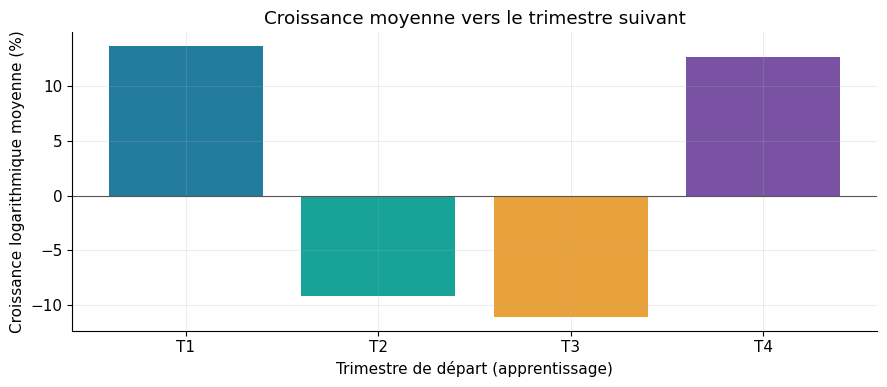

La croissance moyenne varie de -11.08 à 13.66 points de pourcentage logarithmiques. Le profil suggère une saisonnalité à vérifier hors échantillon.


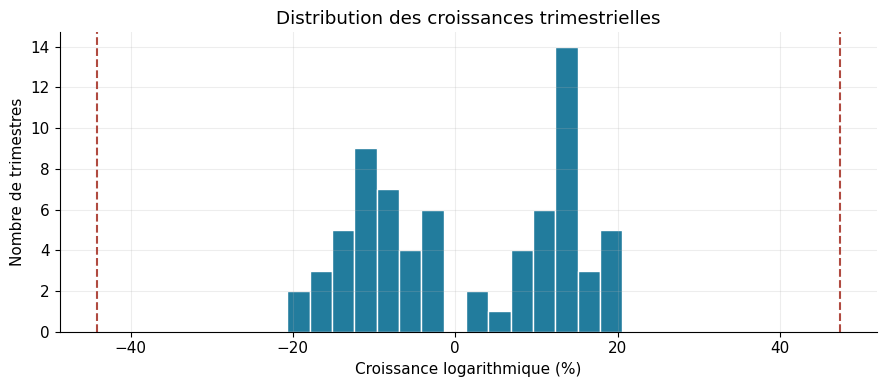

Les bornes interquartiles signalent des valeurs atypiques. Les chocs économiques ne sont pas supprimés : ils font partie de la série réelle.


In [4]:
# Exploration avant évaluation : pas de cible de test utilisée.
expl=df.loc[:test.index.min()].copy()
season=train.groupby(train.index.quarter).g_suivant.mean().reindex([1,2,3,4])*100
q1,q3=expl.croissance.quantile([.25,.75]); iqr=q3-q1
atyp=expl[(expl.croissance<q1-1.5*iqr)|(expl.croissance>q3+1.5*iqr)]
print('Chocs IQR conservés :',len(atyp)); display(atyp)
def save(fig,name):
    fig.tight_layout(); fig.savefig(FIG/name,dpi=220,bbox_inches='tight'); plt.show(); plt.close(fig)
fig,ax=plt.subplots(); ax.bar(['T1','T2','T3','T4'],season,color=['#227c9d','#17a398','#e9a23b','#7952a3']); ax.axhline(0,color='#555',lw=.8); ax.set(title='Croissance moyenne vers le trimestre suivant',xlabel='Trimestre de départ (apprentissage)',ylabel='Croissance logarithmique moyenne (%)'); save(fig,'fig2_description.png')
print(f'La croissance moyenne varie de {season.min():.2f} à {season.max():.2f} points de pourcentage logarithmiques. Le profil suggère une saisonnalité à vérifier hors échantillon.')
fig,ax=plt.subplots(); ax.hist(expl.croissance.dropna()*100,bins=15,color='#227c9d',edgecolor='white'); ax.axvline((q1-1.5*iqr)*100,color='#b04a40',ls='--'); ax.axvline((q3+1.5*iqr)*100,color='#b04a40',ls='--'); ax.set(title='Distribution des croissances trimestrielles',xlabel='Croissance logarithmique (%)',ylabel='Nombre de trimestres'); save(fig,'fig_exploration_3.png')
print('Les bornes interquartiles signalent des valeurs atypiques. Les chocs économiques ne sont pas supprimés : ils font partie de la série réelle.')


## 3. Ridge et protocole expérimental
Ridge minimise $\sum_t(y_t-\beta_0-\sum_j\beta_j z_{tj})^2+\alpha\sum_j\beta_j^2$. Les $z$ sont les variables standardisées, $y$ la croissance suivante, $\beta$ les coefficients appris et $\alpha$ la pénalité. La valeur prévue est $x_t e^{\hat y_t}$. Une forte pénalité réduit les coefficients ; le nombre de retards $L$ règle la mémoire du modèle. Ridge est préférable ici à une forêt aléatoire plus flexible sur un petit échantillon. Le numéro précis de Ridge n'est pas fourni dans le catalogue transmis (régressions : 1 à 7), à vérifier dans le cours. La référence prédit simplement $x_t$. On choisit la configuration par RMSE moyen des 5 plis, sans test.

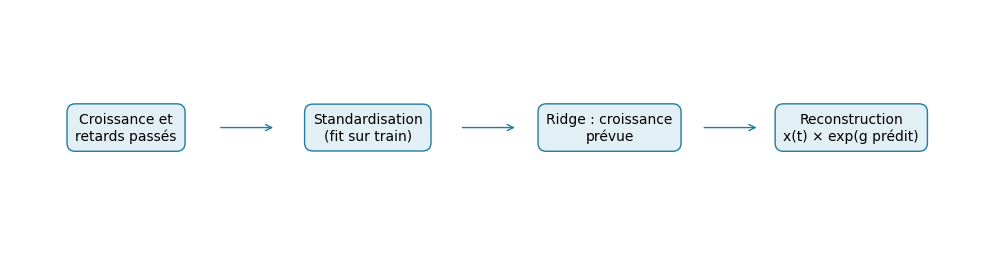

,L,alpha,RMSE validation,MAPE validation
5,2,0.01,155.451890,3.253102
6,2,0.10,155.686944,3.272931
11,3,0.10,157.935302,3.219262
10,3,0.01,158.090657,3.198347
0,1,0.01,162.684919,3.279134
7,2,1.00,163.859503,3.373064
1,1,0.10,165.218812,3.345184
12,3,1.00,165.973913,3.426855
2,1,1.00,182.956646,3.682297
13,3,10.00,193.049506,3.836286


Configuration retenue : L = 2 alpha = 0.01


In [5]:
fig,ax=plt.subplots(figsize=(10,2.8)); ax.axis('off')
labels=['Croissance et\nretards passés','Standardisation\n(fit sur train)','Ridge : croissance\nprévue','Reconstruction\nx(t) × exp(g prédit)']
for j,label in enumerate(labels):
    x=.12+j*.25; ax.text(x,.52,label,ha='center',va='center',transform=ax.transAxes,bbox=dict(boxstyle='round,pad=.6',fc='#e2eff5',ec='#227c9d'),fontsize=10)
    if j<3: ax.annotate('',xy=(x+.155,.52),xytext=(x+.095,.52),xycoords='axes fraction',arrowprops=dict(arrowstyle='->',color='#227c9d'))
save(fig,'schema_ridge.png')

def features(L): return ['croissance']+[f'croiss_retard_{k}' for k in range(1,L+1)]+['T_2','T_3','T_4']
def pipe(alpha): return Pipeline([('scale',StandardScaler()),('ridge',Ridge(alpha=alpha))])
def metrics(y,p):
    y=np.asarray(y); p=np.asarray(p)
    return np.sqrt(np.mean((y-p)**2)),100*np.mean(np.abs((y-p)/y))
def predict(model,part,L): return part.export_services.to_numpy()*np.exp(model.predict(part[features(L)]))
folds=list(TimeSeriesSplit(n_splits=5,gap=1).split(train))
base_cv=np.array([metrics(train.iloc[b].reel,train.iloc[b].export_services) for a,b in folds])
configs=[]; scores={}
for L in (1,2,3):
    for alpha in (.01,.1,1,10,100):
        cv=[]
        for a,b in folds:
            a=train.iloc[a]; b=train.iloc[b]
            model=pipe(alpha).fit(a[features(L)],a.g_suivant)
            cv.append(metrics(b.reel,predict(model,b,L)))
        arr=np.array(cv); scores[(L,alpha)]=arr
        configs.append({'L':L,'alpha':alpha,'RMSE validation':arr[:,0].mean(),'MAPE validation':arr[:,1].mean()})
ranking=pd.DataFrame(configs).sort_values(['RMSE validation','L','alpha']); display(ranking)
L=int(ranking.iloc[0].L); alpha=float(ranking.iloc[0].alpha); ridge_cv=scores[(L,alpha)]
model=pipe(alpha).fit(train[features(L)],train.g_suivant)
print('Configuration retenue : L =',L,'alpha =',alpha)


## 4. Évaluation finale et interprétation
RMSE en millions USD : pénalise les grosses erreurs. MAPE en % : erreur relative moyenne. Les résultats sont calculés sur les valeurs reconstruites, non sur la croissance. Le gain de RMSE est positif lorsque Ridge améliore la persistance.

,Méthode,RMSE val.,MAPE val.,ET RMSE val.,ET MAPE val.,RMSE test,MAPE test
0,Persistance,498.47,11.47,148.47,0.59,819.11,12.47
1,Ridge,155.45,3.25,60.42,0.65,179.28,2.41


,date,Réel,Persistance,Ridge
0,2023Q1,5676.69,4917.58,5772.54
1,2023Q2,6875.98,5676.69,6511.62
2,2023Q3,6103.39,6875.98,5960.21
3,2023Q4,5616.83,6103.39,5405.77
4,2024Q1,6147.57,5616.83,6229.62
5,2024Q2,7202.94,6147.57,7191.74
6,2024Q3,6607.27,7202.94,6501.10
7,2024Q4,5730.33,6607.27,5909.24


Gain de RMSE : 78.11 % | Objectif atteint : True
Plus forte erreur : 2023Q2 -364.36 M USD


,Coefficient standardisé
T_3,-0.091983
croissance,-0.083745
T_2,-0.054887
croiss_retard_1,-0.053240
croiss_retard_2,-0.040483
T_4,-0.035860


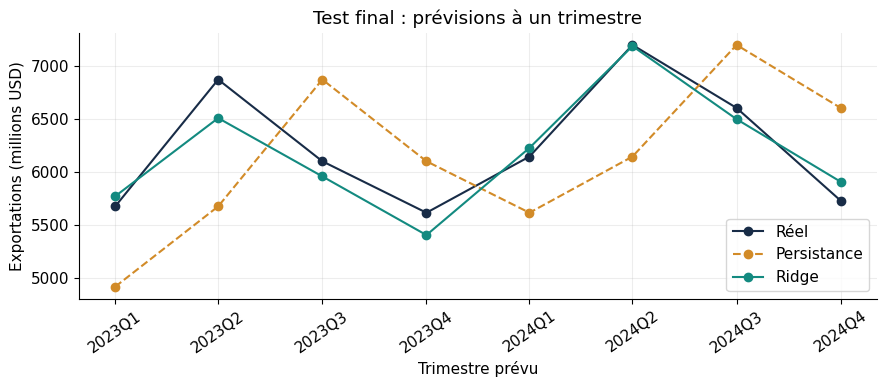

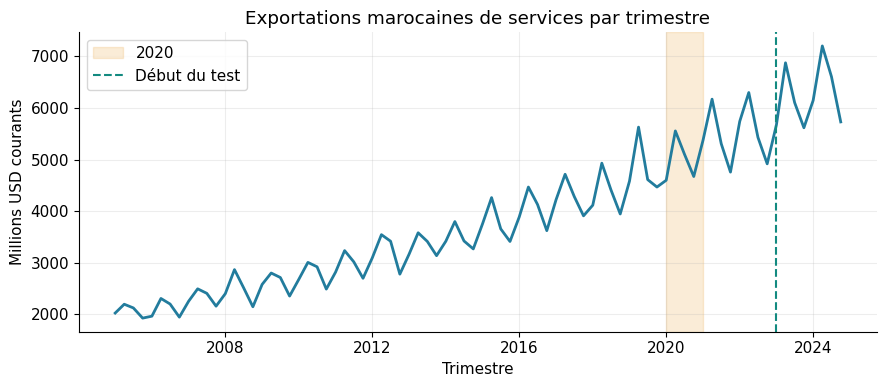

La série passe de 2024.53 à 5730.33 M USD. Les variations de 2020 doivent être replacées dans le contexte de la pandémie.
Ridge : RMSE 179.28, persistance : 819.11 M USD. Gain 78.11 %. Le seuil de 10 % est atteint.


In [6]:
pred=pd.DataFrame({'date':test.date_cible.to_numpy(),'Réel':test.reel.to_numpy(),'Persistance':test.export_services.to_numpy(),'Ridge':predict(model,test,L)})
base_test=metrics(pred.Réel,pred.Persistance); ridge_test=metrics(pred.Réel,pred.Ridge)
train_rmse=metrics(train.reel,predict(model,train,L))[0]
gain=100*(base_test[0]-ridge_test[0])/base_test[0] if base_test[0]>0 else np.nan
resultats=pd.DataFrame([['Persistance',*base_cv.mean(0),*base_cv.std(0),*base_test],['Ridge',*ridge_cv.mean(0),*ridge_cv.std(0),*ridge_test]],columns=['Méthode','RMSE val.','MAPE val.','ET RMSE val.','ET MAPE val.','RMSE test','MAPE test'])
display(resultats.round(2)); display(pred.round(2)); print('Gain de RMSE :',round(gain,2),'% | Objectif atteint :',bool(gain>=10))
pred['Erreur Ridge']=pred.Ridge-pred.Réel
worst=pred.loc[pred['Erreur Ridge'].abs().idxmax()]
coef=pd.Series(model.named_steps['ridge'].coef_,index=features(L)).sort_values(key=abs,ascending=False)
print('Plus forte erreur :',worst.date, round(worst['Erreur Ridge'],2),'M USD'); display(coef.to_frame('Coefficient standardisé'))
fig,ax=plt.subplots(); dates=pd.PeriodIndex(pred.date,freq='Q').to_timestamp(how='end')
for key,color,style in [('Réel','#182c47','-'),('Persistance','#d28b28','--'),('Ridge','#138a80','-')]: ax.plot(dates,pred[key],marker='o',label=key,color=color,ls=style)
ax.set(title='Test final : prévisions à un trimestre',xlabel='Trimestre prévu',ylabel='Exportations (millions USD)'); ax.set_xticks(dates,labels=[str(q) for q in pred.date],rotation=35); ax.legend(); save(fig,'fig3_description.png')
fig,ax=plt.subplots(); ax.plot(df.index.to_timestamp(),df.export_services,color='#227c9d',lw=2); ax.axvspan(pd.Timestamp('2020-01-01'),pd.Timestamp('2020-12-31'),color='#e9a23b',alpha=.2,label='2020'); ax.axvline(test.date_cible.iloc[0].start_time,color='#138a80',ls='--',label='Début du test'); ax.set(title='Exportations marocaines de services par trimestre',xlabel='Trimestre',ylabel='Millions USD courants'); ax.legend(); save(fig,'fig1_description.png')
print(f'La série passe de {df.export_services.iloc[0]:.2f} à {df.export_services.iloc[-1]:.2f} M USD. Les variations de 2020 doivent être replacées dans le contexte de la pandémie.')
print(f'Ridge : RMSE {ridge_test[0]:.2f}, persistance : {base_test[0]:.2f} M USD. Gain {gain:.2f} %. Le seuil de 10 % est '+('atteint.' if gain>=10 else 'non atteint.'))
resultats.to_csv(REP/'metriques_CI08.csv',index=False); pred.to_csv(REP/'predictions_CI08.csv',index=False); ranking.to_csv(REP/'validation_CI08.csv',index=False)


## 5. Export automatique vers Overleaf
Le code ci-dessous reprend la version avancée de ton texte LaTeX et remplace les chiffres manquants par les résultats calculés. Il produit le rapport `.tex`, les cinq PNG et les tableaux CSV. Le groupe, le lien GitHub, le numéro exact de Ridge et les références bibliographiques doivent être vérifiés personnellement. Le ZIP ne contient pas les données brutes de l'OMC (conditions de diffusion à vérifier).

In [7]:
TEMPLATE = "% =====================================================================\n%  RAPPORT À COMPLÉTER\n%  Examen individuel (Partie B) : projet de science des données\n%  appliqué à la finance. S7 FIN et CI, cours BD & DS, ENCG-2026.\n%\n%  Mode d'emploi\n%  1. Remplacez chaque \\acompleter{...} (texte rouge) et chaque\n%     \\acel{...} (cellule rouge) par votre contenu. Rien ne doit rester\n%     en rouge dans la version remise. Après chaque compilation, le\n%     journal indique le nombre d'éléments qui restent à compléter.\n%  2. Compilez avec pdfLaTeX (sur Overleaf : compilateur pdfLaTeX).\n%     Compilez deux fois pour mettre à jour les renvois et les citations.\n%  3. Les figures sont cherchées dans ../figures/ puis dans figures/.\n%     Tant qu'une figure manque, un cadre la remplace : le document\n%     compile toujours. Sur Overleaf, créez un dossier figures/ et\n%     téléversez-y vos images.\n%  4. Citations : chaque source de la liste « Références et citations »\n%     a une clé (par exemple lie1). Citez-la dans le texte avec \\cite{lie1}.\n%  5. Longueur : celle fixée par l'énoncé. Les lignes qui commencent\n%     par % sont des aides : vous pouvez les supprimer.\n%  6. Caractères spéciaux : écrivez \\_ pour un tiret bas (par exemple\n%     \\texttt{n\\_estimators}), \\% pour un pourcentage, \\& pour &.\n%  7. Page de garde : les logos de l'Université Hassan 1er\n%     (logo_universite_hassan1.png) et de l'ENCG Settat\n%     (logo_encg_settat.png) sont fournis : laissez-les à côté de\n%     rapport.tex (ou dans figures/).\n%  8. Votre photo (format identité) : placez-la à côté de rapport.tex,\n%     nommée photo_etudiant.jpg ou photo_etudiant.png. Elle remplace\n%     automatiquement la photo modèle (photo_modele.png), qui s'affiche\n%     en attendant avec la mention « Remplacez par votre photo ».\n%  9. Lien GitHub : remplacez l'adresse dans la commande \\lienDepot\n%     ci-dessous (une seule fois). Il s'affiche sur la page de garde et\n%     en annexe, en rouge tant qu'il n'est pas modifié.\n% 10. Remettez rapport.tex, rapport.pdf, les deux logos et votre photo\n%     dans le dossier rapport/ de votre dépôt CodeApogee-Nom-Groupe.\n% =====================================================================\n\\documentclass[11pt,a4paper]{article}\n\n\\usepackage[utf8]{inputenc}\n\\usepackage[T1]{fontenc}\n\\usepackage{lmodern}\n\\usepackage[french]{babel}\n\\frenchsetup{StandardLists=true}\n\\usepackage[margin=1.8cm]{geometry}\n\\usepackage{amsmath,amssymb}\n\\usepackage{graphicx}\n\\usepackage{booktabs}\n\\usepackage{array}\n\\usepackage{enumitem}\n\\usepackage{xcolor}\n\\usepackage[labelsep=colon]{caption}\n\\PassOptionsToPackage{hyphens}{url}\n\\usepackage[hidelinks]{hyperref}\n\n% ========== Mise en page et commandes du gabarit (ne pas modifier) ==========\n\\addto\\captionsfrench{%\n  \\renewcommand{\\tablename}{Tableau}%\n  \\renewcommand{\\refname}{Références et citations}}\n\\setlist{itemsep=1pt,topsep=3pt}\n\\setlength{\\emergencystretch}{2em}\n\\makeatletter\n\\renewcommand\\paragraph{\\@startsection{paragraph}{4}{\\z@}%\n  {1.2ex \\@plus 0.4ex \\@minus 0.2ex}{-1em}{\\normalfont\\normalsize\\bfseries}}\n\\makeatother\n\\newcolumntype{P}[1]{>{\\raggedright\\arraybackslash}p{#1}}\n\n\\newcounter{nbacompleter}\n\\DeclareRobustCommand{\\acompleter}[1]{%\n  \\stepcounter{nbacompleter}\\textcolor{red}{\\textit{[À compléter : #1]}}}\n\\DeclareRobustCommand{\\acel}[1]{%\n  \\stepcounter{nbacompleter}\\textcolor{red}{\\textit{#1}}}\n% \\insererfigure{fichier}{légende}{étiquette}\n\\newcommand{\\insererfigure}[3]{%\n  \\begin{figure}[htbp]\n    \\centering\n    \\IfFileExists{../figures/#1}{\\includegraphics[width=0.62\\linewidth]{../figures/#1}}{%\n      \\IfFileExists{figures/#1}{\\includegraphics[width=0.62\\linewidth]{figures/#1}}{%\n        \\fbox{\\parbox[c][2.4cm][c]{0.6\\linewidth}{\\centering\\small\n          Figure à insérer : \\texttt{figures/\\detokenize{#1}}}}}}\n    \\caption{#2}\n    \\label{#3}\n  \\end{figure}}\n% ---------- VOTRE LIEN GITHUB : remplacez l'adresse ci-dessous ----------\n\\newcommand{\\lienDepot}{https://github.com/identifiant/CodeApogee-Nom-Groupe}\n% -------------------------------------------------------------------------\n\\newcommand{\\lienParDefaut}{https://github.com/identifiant/CodeApogee-Nom-Groupe}\n\\newcommand{\\afficherlien}{%\n  \\ifx\\lienDepot\\lienParDefaut\n    \\stepcounter{nbacompleter}\\textcolor{red}{\\expandafter\\url\\expandafter{\\lienDepot}}%\n  \\else\n    \\expandafter\\url\\expandafter{\\lienDepot}%\n  \\fi}\n% Photo de l'étudiant(e) : photo_etudiant.jpg ou photo_etudiant.png.\n% Tant qu'elle manque, la photo modèle (photo_modele.png) s'affiche avec la\n% mention « Remplacez par votre photo », et compte comme élément à compléter.\n\\newcommand{\\photo}[1]{\\includegraphics[width=3.5cm,height=4.5cm,keepaspectratio]{#1}}\n\\newcommand{\\insererphoto}{%\n  \\IfFileExists{photo_etudiant.jpg}{\\photo{photo_etudiant.jpg}}{%\n    \\IfFileExists{photo_etudiant.png}{\\photo{photo_etudiant.png}}{%\n    \\IfFileExists{photo_modele.png}{\\stepcounter{nbacompleter}\\photo{photo_modele.png}\\\\[3pt]%\n      {\\scriptsize\\textcolor{red}{\\textit{Remplacez par votre photo}}}}{%\n      \\fbox{\\parbox[c][4.5cm][c]{3.5cm}{\\centering\\small\\textcolor{red}{\\textit{Photo de\\\\ l'étudiant(e)}}\\\\[4pt]\n        \\scriptsize\\texttt{photo\\_etudiant.jpg}}}}}}}\n% Logos de la page de garde : déposez les deux fichiers à côté de rapport.tex\n% (ou dans figures/). Modifiez les noms ci-dessous si vos fichiers s'appellent autrement.\n\\newcommand{\\fichierlogouniv}{logo_universite_hassan1.png}\n\\newcommand{\\fichierlogo}{logo_encg_settat.png}\n% \\chercherimage{fichier}{options}{largeur du cadre}{hauteur du cadre}{texte du cadre}\n\\newcommand{\\chercherimage}[5]{%\n  \\IfFileExists{#1}{\\includegraphics[#2]{#1}}{%\n    \\IfFileExists{figures/#1}{\\includegraphics[#2]{figures/#1}}{%\n      \\IfFileExists{../figures/#1}{\\includegraphics[#2]{../figures/#1}}{%\n        \\fbox{\\parbox[c][#4][c]{#3}{\\centering\\small #5\\\\[2pt]\n          \\tiny\\texttt{\\detokenize{#1}}}}}}}}\n\\newcommand{\\insererlogouniv}{\\chercherimage{\\fichierlogouniv}{height=1.9cm}{5.2cm}{1.9cm}{Logo de l'Université Hassan 1\\ier}}\n\\newcommand{\\insererlogo}{\\chercherimage{\\fichierlogo}{height=2.5cm}{2.5cm}{2.5cm}{Logo de l'ENCG Settat}}\n\\AtEndDocument{\\ifnum\\value{nbacompleter}>0\n  \\typeout{ATTENTION : il reste \\arabic{nbacompleter} élément(s) à compléter.}\\fi}\n% ===========================================================================\n\n\\begin{document}\n\n% =====================================================================\n%  PAGE DE GARDE (non comptée dans la longueur du rapport)\n% =====================================================================\n\\begin{titlepage}\n  \\centering\n  % Logos : Université Hassan 1er à gauche, ENCG Settat à droite\n  \\noindent\n  \\begin{minipage}[c]{0.5\\linewidth}\\raggedright\\insererlogouniv\\end{minipage}%\n  \\begin{minipage}[c]{0.5\\linewidth}\\raggedleft\\IfFileExists{ENCG SETTAT LOGO.png}{\\includegraphics[height=2.5cm]{ENCG SETTAT LOGO.png}}{\\insererlogo}\\end{minipage}\\par\n  \\vspace{0.9cm}\n  {\\large Université Hassan 1\\ier{} de Settat}\\par\n  \\vspace{0.2cm}\n  {\\Large\\bfseries École Nationale de Commerce et de Gestion de Settat}\\par\n  \\vspace{0.1cm}\n  {\\large ENCG Settat}\\par\n  \\vspace{1.6cm}\n  \\rule{\\linewidth}{0.8pt}\\par\n  \\vspace{0.5cm}\n  {\\large Cours BD \\& DS : examen individuel (Partie B)}\\par\n  \\vspace{0.3cm}\n  {\\Large Rapport de projet de science des données appliquée au commerce international}\\par\n  \\vspace{0.7cm}\n  {\\LARGE\\bfseries CI08 : Prévision des exportations de services du Maroc}\\par\n  \\vspace{0.5cm}\n  \\rule{\\linewidth}{0.8pt}\\par\n  \\vfill\n  \\begin{minipage}[c]{0.66\\linewidth}\n  \\large\n  \\begin{tabular}{@{}ll@{}}\n    Réalisé par          & EL FALH Meryem-Chama \\\\[3pt]\n    Code Apogée          & 23008920 \\\\[3pt]\n    Groupe et filière    & \\acel{groupe}, S7 CI \\\\[3pt]\n    Algorithme principal & Ridge (régression) \\\\[3pt]\n    Enseignant        & {A. Larhlimi} \\\\[3pt]\n  \\end{tabular}\n  \\end{minipage}\\hfill\n  \\begin{minipage}[c]{0.3\\linewidth}\n  \\centering\\IfFileExists{photo_modele.jpeg}{\\includegraphics[width=3cm]{photo_modele.jpeg}}{\\insererphoto}\n\\end{minipage}\\par\n  \\vspace{0.8cm}\n  {\\large\\textbf{Dépôt GitHub :} \\afficherlien}\\par\n  \\vfill\n  {\\large Année universitaire 2026-2027}\\par\n  \\vspace{0.2cm}\n  Remis le \\today\n\\end{titlepage}\n\n% =====================================================================\n\\section{Introduction}\n\\label{sec:introduction}\n% 8 à 12 lignes. Elle reprend la cellule d'en-tête du notebook.\n% =====================================================================\n\\paragraph{Contexte.} Le Maroc est un exportateur net de services : selon l'OMC, ses exportations de services sont passées d'environ 13,3 milliards de dollars en 2020 à 27,2 milliards en 2024, portées notamment par le tourisme \\cite{donnees}. Les voyages représentent plus de 40\\,\\% des exportations de services commerciaux marocains \\cite{wits}. Anticiper ces recettes en devises intéresse l'Office des Changes, le ministère de l'Économie et des Finances et les opérateurs du tourisme et des services, pour préparer le budget, la politique de change et la promotion à l'export.\n\n\\paragraph{Problématique.} Un modèle de régression Ridge, construit à partir de la croissance passée des exportations marocaines de services, prévoit-il la valeur du trimestre suivant plus précisément qu'une simple règle de persistance ?\n\n\\paragraph{Objectif mesurable.} Métrique principale : racine de l'erreur quadratique moyenne (RMSE, en millions de dollars) ; métrique secondaire : erreur absolue moyenne en pourcentage (MAPE). Référence naïve : persistance, qui prévoit pour le trimestre suivant la valeur du trimestre courant. Jeu de test : les 8 derniers trimestres de la série. Seuil de réussite fixé avant de voir les résultats : un RMSE de test inférieur d'au moins 10\\,\\% à celui de la persistance.\n\n\\paragraph{Nature du problème.} Régression supervisée sur série temporelle : la cible est la croissance logarithmique des exportations au trimestre suivant (grandeur continue), prédite à un pas d'avance à partir de la croissance passée et de la saisonnalité.\n\n\\paragraph{Organisation du rapport.} La section~\\ref{sec:etat} présente l'état de l'art et la section~\\ref{sec:travaux} les travaux liés. Les sections~\\ref{sec:donnees} à~\\ref{sec:protocole} décrivent les données, leur exploration, leur préparation, l'algorithme retenu et le protocole expérimental. La section~\\ref{sec:resultats} présente les résultats, discutés en section~\\ref{sec:discussion}, avant la conclusion (section~\\ref{sec:conclusion}).\n\n% =====================================================================\n\\section{État de l'art}\n\\label{sec:etat}\n% 6 à 10 lignes et le tableau. L'état de l'art présente les GRANDES\n% FAMILLES de méthodes utilisées pour ce type de problème (approches\n% statistiques ou économétriques classiques, apprentissage automatique,\n% référence naïve habituelle du domaine), avec leurs atouts et limites.\n% Chaque affirmation est appuyée par une citation \\cite{...}.\n% =====================================================================\nLa prévision de séries commerciales et touristiques relève de trois grandes familles de méthodes : les règles naïves, les modèles statistiques de séries temporelles (ARIMA et variantes saisonnières) et l'apprentissage automatique \\cite{etat1}. La revue de Song, Qiu et Park, portant sur 211 articles, conclut qu'aucune méthode ne domine dans toutes les situations \\cite{etat1}. Les règles de persistance, simples, servent de point de comparaison obligé \\cite{etat2}. Sur des séries courtes, les modèles ARIMA restent compétitifs face aux méthodes d'apprentissage automatique \\cite{etat3}, qui demandent davantage de données. Les régressions régularisées comme Ridge limitent le surapprentissage quand les observations sont peu nombreuses \\cite{ridge}.\n\n\\begin{table}[htbp]\n  \\centering\n  \\caption{Panorama des approches pour ce type de problème}\n  \\label{tab:etat}\n  \\small\n  \\begin{tabular}{@{}P{3cm} P{4.3cm} P{3.5cm} P{3.5cm} l@{}}\n    \\toprule\n    Approche & Principe & Atouts & Limites & Réf. \\\\\n    \\midrule\n    Référence naïve : persistance & Prévoit la valeur suivante par la dernière valeur observée (ou celle de la même période un an plus tôt) & Aucun paramètre ; difficile à battre à court terme & Ignore la tendance et les chocs & \\cite{etat2} \\\\\n    Modèles statistiques (ARIMA, SARIMA) & Expliquent la série par ses valeurs et erreurs passées, avec différenciation et saisonnalité & Adaptés aux séries courtes ; interprétables & Hypothèse linéaire ; choix des ordres délicat & \\cite{etat1,etat3} \\\\\n    Apprentissage automatique (Ridge, forêts, réseaux) & Apprennent une relation entre variables passées et valeur à prévoir & Captent des relations complexes selon le modèle ; intègrent des variables externes & Exigent plus de données ; risque de surapprentissage & \\cite{etat1,lie1} \\\\\n    \\bottomrule\n  \\end{tabular}\n\\end{table}\n\n% =====================================================================\n\\section{Travaux liés}\n\\label{sec:travaux}\n% Deux ou trois ÉTUDES PRÉCISES qui traitent un problème proche du vôtre\n% (même question, mêmes données ou même méthode). Pour chacune : données,\n% méthode, résultat principal, et ce qui distingue votre travail.\n% =====================================================================\n\\begin{table}[htbp]\n  \\centering\n  \\caption{Travaux liés}\n  \\label{tab:travaux}\n  \\small\n  \\begin{tabular}{@{}P{2.4cm} P{2.8cm} P{2.8cm} P{3.4cm} P{3.8cm}@{}}\n    \\toprule\n    Travail & Données & Méthode & Résultat principal & Différence avec ce travail \\\\\n    \\midrule\n    Lei, Chen et Chu, 2025 \\cite{lie1} & Arrivées mensuelles de touristes à Macao, 2010-2019, et variables externes & SARIMAX avec grille de paramètres et validation à origine glissante, comparé à LSTM, forêt aléatoire, XGBoost & SARIMAX amélioré : MAPE 5,7\\,\\% ; LSTM : 6,6\\,\\% ; forêt aléatoire et XGBoost : plus de 15\\,\\% & Ici : recettes d'exportation de services du Maroc, série courte, modèle Ridge, référence de persistance \\\\\n    Law, Li, Fong et Han, 2019 \\cite{lie2} & Arrivées mensuelles de touristes à Macao et données de requêtes de recherche & LSTM avec mécanisme d'attention (apprentissage profond) & Erreurs (MAPE, MAE, RMSE) plus faibles que celles des modèles de comparaison & Ici : sans données de recherche, modèle linéaire simple adapté à peu d'observations \\\\\n    \\bottomrule\n  \\end{tabular}\n\\end{table}\n\n\\paragraph{Positionnement.} Ces études portent sur les arrivées touristiques et non sur les recettes d'exportation de services. Elles montrent pourtant que, sur des séries courtes, un modèle simple et bien réglé rivalise avec des modèles complexes \\cite{lie1}, alors que l'apprentissage profond peut l'emporter quand il dispose de données supplémentaires comme les requêtes de recherche \\cite{lie2}. Ce travail reprend la validation chronologique à origine glissante et l'applique aux exportations de services du Maroc, avec une comparaison explicite à la persistance.\n\n% =====================================================================\n\\section{Jeu de données}\n\\label{sec:donnees}\n% =====================================================================\n\\begin{itemize}\n  \\item \\textbf{Nom et source :} Statistiques de l'OMC sur le commerce des services commerciaux, exportations du Maroc \\cite{donnees}, \\url{https://stats.wto.org/}\n@@DATE_LINE@@\n  \\item \\textbf{Licence ou conditions d'utilisation :} non précisée par la source\n  \\item \\textbf{Cadre commercial :} pays déclarant : Maroc ; partenaire : monde entier ; secteur : total des services commerciaux (nomenclature des services, sans code SH, donc aucun changement de nomenclature SH à traiter) ; flux : exportations ; devise : dollars américains courants ; grandeur : valeur.\n@@SIZE_LINE@@\n  \\item \\textbf{Unité d'observation :} un trimestre, pour le Maroc\n  \\item \\textbf{Variable cible :} \\texttt{g\\_suivant}, croissance logarithmique des exportations entre le trimestre courant et le suivant, $\\ln(x_{t+1}/x_t)$\n  \\item \\textbf{Adéquation :} série officielle et régulière du phénomène à prévoir, qui permet une prévision à un pas et une comparaison honnête avec la persistance\n  \\item \\textbf{Limites :} peu d'observations ; rupture de 2020 liée à la pandémie, puis forte reprise ; valeurs en dollars courants (effets de change et de prix) ; total des services seulement, sans détail par partenaire ni par secteur ; révisions possibles des séries\n\\end{itemize}\n\n% Cinq à huit variables suffisent. Ajoutez ou retirez des lignes.\n% Les variables que vous créez figurent aussi ici, avec leur formule.\n\\begin{table}[htbp]\n  \\centering\n  \\caption{Dictionnaire des principales variables}\n  \\label{tab:dictionnaire}\n  \\small\n  \\begin{tabular}{@{}l P{4.0cm} l l l c@{}}\n    \\toprule\n    Variable & Description & Type & Unité & Rôle & Manquants (\\%) \\\\\n    \\midrule\n    \\texttt{date} & Fin du trimestre observé & date & trimestre & date & 0 \\\\\n    \\texttt{export\\_services} & Exportations de services commerciaux du Maroc, $x_t$, en millions de dollars courants & numérique & M USD & base & 0 \\\\\n    \\texttt{croissance} & Croissance logarithmique $g_t = \\ln(x_t / x_{t-1})$ & numérique & sans unité & explicative & 0 \\\\\n    \\texttt{croiss\\_retard\\_k} & Croissance retardée de $k$ trimestres, $g_{t-k}$, avec $k = 1, 2, 3$ & numérique & sans unité & explicative & 0 \\\\\n    \\texttt{T\\_2, T\\_3, T\\_4} & Indicatrices du trimestre (le premier est la référence) & binaire & sans unité & explicative & 0 \\\\\n    \\texttt{g\\_suivant} & Croissance au trimestre suivant, $g_{t+1} = \\ln(x_{t+1} / x_t)$ & numérique & sans unité & cible & 0 \\\\\n    \\bottomrule\n  \\end{tabular}\n\\end{table}\n\n% =====================================================================\n\\section{Exploration}\n\\label{sec:exploration}\n% =====================================================================\n@@STATS_LINE@@\n\n@@QUALITY_LINE@@\n\n\\insererfigure{fig1_description.png}{Exportations marocaines de services par trimestre (millions USD courants)}{fig:1}\n\n@@FIG1_LINE@@\n\n\\insererfigure{fig2_description.png}{Croissance logarithmique moyenne vers le trimestre suivant, selon le trimestre de départ}{fig:2}\n\n@@FIG2_LINE@@\n\n\\insererfigure{fig_exploration_3.png}{Distribution de la croissance logarithmique trimestrielle (apprentissage)}{fig:exploration3}\n\\noindent\\textbf{Lecture.} La distribution et la règle interquartile permettent de repérer les chocs sans les supprimer automatiquement.\n\n% =====================================================================\n\\section{Préparation}\n\\label{sec:preparation}\n% =====================================================================\n\\begin{itemize}\n  \\item \\textbf{Nettoyage :} tri chronologique, contrôle des valeurs manquantes et des doublons de date, suppression des premières lignes sans retards disponibles et de la dernière ligne sans cible.\n  \\item \\textbf{Variables créées :} croissance logarithmique, trois retards de croissance, indicatrices de trimestre et cible décalée d'un trimestre ; formules dans le tableau~\\ref{tab:dictionnaire}.\n  \\item \\textbf{Encodage et mise à l'échelle :} indicatrices pour le trimestre ; standardisation (\\texttt{StandardScaler}) ajustée sur l'apprentissage seulement, car Ridge est sensible à l'échelle des variables.\n\\end{itemize}\n\n\\paragraph{Prévention des fuites.}\n\\begin{itemize}\n  \\item[$\\boxtimes$] Transformations ajustées sur l'apprentissage seulement, dans un \\texttt{Pipeline}.\n  \\item[$\\boxtimes$] Découpage chronologique, sans mélange (données datées).\n  \\item[$\\boxtimes$] Variables construites avec le passé seulement ; écart de $h$ observations si la cible porte sur un horizon $h$.\n  \\item[$\\boxtimes$] Aucune variable ne contient la cible, même indirectement.\n  \\item[$\\boxtimes$] Jeu de test utilisé une seule fois, à la fin.\n\\end{itemize}\nL'alignement a été vérifié en affichant les premières lignes du tableau final (date, croissance, retards, cible) : pour chaque ligne, la cible est la croissance entre $t$ et $t+1$ et aucune variable ne porte d'information postérieure à $t$.\n\n% =====================================================================\n\\section{Algorithme}\n\\label{sec:algorithme}\n% 6 à 10 lignes pour le principe.\n% =====================================================================\n\\paragraph{Choix.} L'algorithme retenu est la régression Ridge (numéro exact à vérifier dans le support du cours). Il convient à une série courte : la pénalité $\\ell_2$ stabilise les coefficients quand les variables retardées sont corrélées \\cite{ridge}, et le modèle reste interprétable. L'alternative plausible, la forêt aléatoire, a été écartée : elle est moins interprétable, plus exposée au surapprentissage sur un petit échantillon et ne prolonge pas une tendance.\n\n\\paragraph{Principe.} Ridge ajuste une régression linéaire en minimisant l'erreur quadratique, à laquelle s'ajoute une pénalité sur la taille des coefficients. Les variables sont d'abord standardisées, puis le modèle prédit la croissance du trimestre suivant ; la valeur prévue est reconstruite par $\\hat{x}_{t+1} = x_t \\, e^{\\hat{y}}$. La persistance correspond au cas particulier d'une croissance prévue nulle. Implémentation avec scikit-learn \\cite{sklearn}, d'après le support du cours \\cite{support}.\n\n\\paragraph{Formule essentielle.}\n\\begin{equation}\n  \\hat{\\boldsymbol\\beta} = \\arg\\min_{\\beta_0,\\boldsymbol\\beta} \\sum_{t=1}^{n} \\Big( y_t - \\beta_0 - \\sum_{j=1}^{p} \\beta_j z_{t,j} \\Big)^2 + \\alpha \\sum_{j=1}^{p} \\beta_j^2\n  \\label{eq:principale}\n\\end{equation}\noù $y_t$ est la croissance logarithmique du trimestre suivant, $z_{t,j}$ la $j$-ème variable explicative standardisée (croissances retardées et indicatrices de trimestre), $p$ leur nombre, $n$ le nombre d'observations d'apprentissage, $\\beta_0$ la constante, $\\beta_j$ les coefficients et $\\alpha \\ge 0$ le coefficient de pénalisation.\n\n\\insererfigure{schema_ridge.png}{Principe de la prévision Ridge à un trimestre}{fig:ridge}\n\n\\paragraph{Paramètres appris.} La constante $\\beta_0$ et les coefficients $\\beta_j$ de chaque variable. Les hyperparamètres $\\alpha$ et $L$ ne sont pas appris : ils sont choisis par validation.\n\n\\begin{table}[htbp]\n  \\centering\n  \\caption{Hyperparamètres étudiés}\n  \\label{tab:hyper}\n  \\small\n  \\begin{tabular}{@{}l P{5.0cm} P{3.3cm} l@{}}\n    \\toprule\n    Hyperparamètre & Rôle et effet attendu & Valeurs testées & Valeur retenue \\\\\n    \\midrule\n@@ALPHA_LINE@@\n@@L_LINE@@\n    \\bottomrule\n  \\end{tabular}\n\\end{table}\n\n% =====================================================================\n\\section{Protocole expérimental}\n\\label{sec:protocole}\n% =====================================================================\n\\begin{table}[htbp]\n  \\centering\n  \\caption{Découpage des données}\n  \\label{tab:decoupage}\n  \\small\n  \\begin{tabular}{@{}l l r@{}}\n    \\toprule\n    Ensemble & Période ou proportion & Observations \\\\\n    \\midrule\n@@TRAIN_LINE@@\n    Validation & validation croisée chronologique, 5 plis, dans l'apprentissage & inclus \\\\\n@@TEST_LINE@@\n    \\bottomrule\n  \\end{tabular}\n\\end{table}\n\n\\begin{itemize}\n  \\item \\textbf{Référence naïve :} persistance, qui prévoit pour le trimestre suivant la valeur du trimestre courant ; c'est la règle de comparaison usuelle en prévision \\cite{etat2}.\n  \\item \\textbf{Validation :} \\texttt{TimeSeriesSplit}, 5 plis chronologiques, 15 configurations essayées (3 valeurs de $L$ et 5 valeurs de $\\alpha$), choisies sur l'apprentissage seulement.\n  \\item \\textbf{Métrique principale :} RMSE, en millions de dollars, calculée sur les valeurs reconstruites ; elle pénalise les grosses erreurs, qui comptent pour une prévision de recettes.\n  \\item \\textbf{Métriques secondaires :} MAPE (en \\%), qui rend l'erreur comparable dans le temps malgré la hausse de la série.\n  \\item \\textbf{Graine aléatoire :} 42.\n\\end{itemize}\n\n% =====================================================================\n\\section{Résultats}\n\\label{sec:resultats}\n% Les FAITS : chiffres, figure, erreurs. Leur interprétation va dans\n% la section Discussion des résultats.\n% =====================================================================\n% En non supervisé ou en renforcement, adaptez les colonnes (silhouette,\n% variance expliquée, rendement, ratio de Sharpe, perte maximale...),\n% selon la section 3.3 de l'énoncé.\n\\begin{table}[htbp]\n  \\centering\n  \\caption{Comparaison de la référence naïve et du modèle}\n  \\label{tab:resultats}\n  \\small\n  \\begin{tabular}{@{}l cc cc@{}}\n    \\toprule\n    & \\multicolumn{2}{c}{RMSE (millions USD)} & \\multicolumn{2}{c}{MAPE (\\%)} \\\\\n    \\cmidrule(lr){2-3}\\cmidrule(lr){4-5}\n    Modèle & Validation & Test & Validation & Test \\\\\n    \\midrule\n@@BASE_LINE@@\n@@RIDGE_LINE@@\n    \\bottomrule\n  \\end{tabular}\n\\end{table}\n\n\\insererfigure{fig3_description.png}{Jeu de test : prévision à un trimestre, persistance et Ridge, contre valeur réelle}{fig:3}\n\n@@RESULT_LINE@@\n\n@@ERROR_LINE@@\n\n\\begin{table}[htbp]\n  \\centering\n  \\caption{Prédictions sur des observations non utilisées pour l'apprentissage}\n  \\label{tab:illustration}\n  \\small\n  \\begin{tabular}{@{}l l l P{7cm}@{}}\n    \\toprule\n    Observation & Prédiction & Valeur réelle & Commentaire \\\\\n    \\midrule\n@@PRED_ROWS@@\n    \\bottomrule\n  \\end{tabular}\n\\end{table}\n\n% =====================================================================\n\\section{Discussion des résultats}\n\\label{sec:discussion}\n% 8 à 12 lignes : ce que les résultats veulent dire, et leurs limites.\n% =====================================================================\n@@OBJECTIVE_LINE@@\n\n@@INTERPRET_LINE@@\n\n@@OVERFIT_LINE@@\n\n@@COMPARE_LINE@@\n\n@@LIMIT_LINE@@\n\n\\paragraph{Pistes d'amélioration.} Première piste : ajouter des variables externes disponibles avec un décalage (arrivées de touristes, taux de change dirham-dollar, demande de l'Union européenne). Seconde piste : comparer à un modèle SARIMA avec la même validation chronologique.\n\n% =====================================================================\n\\section{Conclusion}\n\\label{sec:conclusion}\n% 4 à 6 lignes : réponse directe à la problématique, apport, perspective.\n% =====================================================================\n@@CONCLUSION_LINE@@\n\n% =====================================================================\n%  RÉFÉRENCES ET CITATIONS\n%  Format : Auteur(s), « titre », revue ou éditeur, volume, pages, année.\n%  Pour une page web : organisme, titre, URL, date de consultation.\n%  Chaque référence doit être citée au moins une fois dans le texte.\n% =====================================================================\n\\begin{thebibliography}{9}\n@@SOURCE_LINE@@\n@@WITS_LINE@@\n  \\bibitem{etat1} H.~Song, R.~T.~R. Qiu et J.~Park, « A review of research on tourism demand forecasting », \\textit{Annals of Tourism Research}, vol.~75, p.~338-362, 2019, \\url{https://doi.org/10.1016/j.annals.2018.12.001}.\n  \\bibitem{etat2} R.~J. Hyndman et G.~Athanasopoulos, \\textit{Forecasting: Principles and Practice}, 3\\textsuperscript{e} éd., OTexts, 2021.\n  \\bibitem{etat3} V.~I. Kontopoulou \\textit{et al.}, « A Review of ARIMA vs. Machine Learning Approaches for Time Series Forecasting in Data Driven Networks », \\textit{Future Internet}, vol.~15, n\\textsuperscript{o}~8, art.~255, 2023, \\url{https://doi.org/10.3390/fi15080255}.\n  \\bibitem{ridge} A.~E. Hoerl et R.~W. Kennard, « Ridge regression: biased estimation for nonorthogonal problems », \\textit{Technometrics}, vol.~12, n\\textsuperscript{o}~1, p.~55-67, 1970.\n  \\bibitem{lie1} C.~F. Lei, F.~Chen et C.~W. Chu, « Optimizing SARIMAX Model with Big Data to Predict Gaming Tourism Destination Demand », \\textit{Mathematics}, vol.~13, n\\textsuperscript{o}~20, art.~3276, 2025, \\url{https://doi.org/10.3390/math13203276}.\n  \\bibitem{lie2} R.~Law, G.~Li, D.~K.~C. Fong et X.~Han, « Tourism demand forecasting: A deep learning approach », \\textit{Annals of Tourism Research}, vol.~75, p.~410-423, 2019, \\url{https://doi.org/10.1016/j.annals.2019.01.014}.\n  \\bibitem{sklearn} F.~Pedregosa \\textit{et al.}, « Scikit-learn: Machine Learning in Python », \\textit{Journal of Machine Learning Research}, vol.~12, p.~2825-2830, 2011.\n  \\bibitem{support} Support du cours BD \\& DS, notebook \\texttt{Tp\\_ML.ipynb}, ENCG-2026.\n\\end{thebibliography}\n\n% =====================================================================\n%  ANNEXES\n% =====================================================================\n\\appendix\n\n\\section{Reproduction}\n\\label{ann:reproduction}\nVersion corrigée : étiquette \\texttt{remise-finale} du dépôt \\afficherlien.\n\\begin{enumerate}\n  \\item Cloner le dépôt : \\texttt{git clone} suivi du lien ci-dessus.\n  \\item Installer les dépendances : \\texttt{pip install -r requirements.txt}.\n  \\item Exécuter \\texttt{notebooks/projet\\_CI08.ipynb} avec « Redémarrer et tout exécuter ».\n\\end{enumerate}\n\n\\section{Déclaration des outils d'IA}\n\\label{ann:ia}\n% Reprend le fichier DECLARATION_IA.md du dépôt.\n\\begin{table}[htbp]\n  \\centering\n  \\caption{Ressources et outils d'IA utilisés}\n  \\label{tab:ia}\n  \\small\n  \\begin{tabular}{@{}P{3cm} P{4.8cm} P{3.3cm} P{4.4cm}@{}}\n    \\toprule\n    Outil ou ressource & Usage précis & Parties concernées & Vérification effectuée \\\\\n    \\midrule\n@@AI_LINE@@\n    \\bottomrule\n  \\end{tabular}\n\\end{table}\n\n\\end{document}\n"

In [8]:
def f(x): return f'{x:,.2f}'.replace(',','~').replace('.',',')
def q(x): return str(x).replace('Q',' T')
def esc(s): return str(s).replace('_',r'\_').replace('%',r'\%').replace('&',r'\&')
rowend=r' \\'
last=df.export_services.iloc[-1]; first=df.export_services.iloc[0]
change=(last/first-1)*100
att='atteint' if gain>=10 else 'non atteint'
beats='bat' if gain>0 else ('égale' if gain==0 else 'ne bat pas')
relation='une amélioration' if gain>0 else 'une dégradation' if gain<0 else 'aucune variation'
strong=', '.join(r'\texttt{'+esc(x)+'}' for x in coef.index[:3])
def metricrow(name,cv,te):
    return name+' & '+f(cv[:,0].mean())+r' $\pm$ '+f(cv[:,0].std())+' & '+f(te[0])+' & '+f(cv[:,1].mean())+r' $\pm$ '+f(cv[:,1].std())+' & '+f(te[1])+rowend
D={
'DATE_LINE':r"  \item \textbf{Date d'extraction :} "+DATE_EXTRACTION,
'SIZE_LINE':r'  \item \textbf{Taille :} '+str(len(df))+' observations trimestrielles, une variable de valeur et une date, de '+q(df.index.min())+' à '+q(df.index.max())+'.',
'STATS_LINE':r'\paragraph{Statistiques descriptives.} La série compte '+str(len(df))+' trimestres. Moyenne : '+f(df.export_services.mean())+' millions USD ; écart-type : '+f(df.export_services.std())+' ; minimum : '+f(df.export_services.min())+' ('+q(df.export_services.idxmin())+') ; maximum : '+f(df.export_services.max())+' ('+q(df.export_services.idxmax())+r'). La croissance logarithmique moyenne est de '+f(df.croissance.mean()*100)+r'\,\%.',
'QUALITY_LINE':r'\paragraph{Qualité des données.} Extraction : '+str(missing)+' valeurs manquantes et '+str(duplicates)+' dates en double. Après nettoyage, aucun trou trimestriel. La règle interquartile appliquée avant le test signale '+str(len(atyp))+' chocs ; ils sont conservés.',
'FIG1_LINE':r'\noindent\textbf{Lecture de la figure~\ref{fig:1}.} La valeur passe de '+f(first)+' à '+f(last)+r' millions USD, soit '+f(change)+r'\,\% entre les deux extrémités. La transformation logarithmique permet de modéliser les variations relatives plutôt que les niveaux.',
'FIG2_LINE':r'\noindent\textbf{Lecture de la figure~\ref{fig:2}.} Dans l’apprentissage, les croissances logarithmiques moyennes vont de '+f(season.min())+' à '+f(season.max())+r'\,\% selon le trimestre de départ. Les indicatrices permettent de prendre en compte ce profil saisonnier potentiel.',
'ALPHA_LINE':r'    \texttt{alpha} ($\alpha$) & Force de la pénalité $\ell_2$ & 0,01 ; 0,1 ; 1 ; 10 ; 100 & '+f(alpha)+rowend,
'L_LINE':r'    $L$ (retards) & Mémoire du modèle, en trimestres & 1 ; 2 ; 3 & '+str(L)+rowend,
'TRAIN_LINE':'    Apprentissage & du '+q(train.date_cible.min())+' au '+q(train.date_cible.max())+' & '+str(len(train))+rowend,
'TEST_LINE':'    Test & du '+q(test.date_cible.min())+' au '+q(test.date_cible.max())+' & 8'+rowend,
'BASE_LINE':metricrow('Référence : persistance',base_cv,base_test),
'RIDGE_LINE':metricrow('Ridge',ridge_cv,ridge_test),
'RESULT_LINE':r'\paragraph{Lecture des résultats.} RMSE de Ridge : '+f(ridge_test[0])+' millions USD contre '+f(base_test[0])+r' pour la persistance. Le gain relatif est de '+f(gain)+r'\,\% (positif si Ridge améliore la référence). La figure~\ref{fig:3} compare les trois trajectoires sur les mêmes dates.',
'ERROR_LINE':r'\paragraph{Analyse des erreurs.} La plus forte erreur absolue de Ridge est observée en '+q(worst.date)+' : '+f(abs(worst['Erreur Ridge']))+' millions USD. Le modèle '+('surestime' if worst['Erreur Ridge']>0 else 'sous-estime' if worst['Erreur Ridge']<0 else 'reproduit')+' la valeur réelle.',
'PRED_ROWS':'\n'.join(q(r['date'])+' & '+f(r['Ridge'])+' & '+f(r['Réel'])+' & '+('Surestimation' if r['Erreur Ridge']>0 else 'Sous-estimation' if r['Erreur Ridge']<0 else 'Prévision exacte')+rowend for _,r in pred.head(3).iterrows()),
'OBJECTIVE_LINE':r"\paragraph{Réponse à l'objectif.} Le seuil de réduction de 10\,\% du RMSE est "+att+r' : gain de '+f(gain)+r'\,\%.',
'INTERPRET_LINE':r'\paragraph{Interprétation.} Le test indique '+relation+' par rapport à la persistance. Les coefficients standardisés les plus élevés en valeur absolue concernent '+strong+'. Il ne s’agit pas de liens causaux.',
'OVERFIT_LINE':r'\paragraph{Surapprentissage et généralisation.} Le RMSE sur l’apprentissage est de '+f(train_rmse)+' contre '+f(ridge_test[0])+' sur le test. Les RMSE des cinq plis varient de '+f(ridge_cv[:,0].min())+' à '+f(ridge_cv[:,0].max())+' (écart-type : '+f(ridge_cv[:,0].std())+'). Un écart peut aussi refléter une rupture économique ; ces chiffres ne suffisent pas à prouver un surapprentissage.',
'COMPARE_LINE':r'\paragraph{Comparaison avec les travaux liés.} Comme Lei et al. \cite{lie1}, cette étude compare un modèle à une référence sur des données temporelles. Les cibles et les jeux de données diffèrent ; les scores ne sont pas directement comparables.',
'LIMIT_LINE':r'\paragraph{Limites et biais.} La série comporte '+str(len(df))+' trimestres en dollars courants, avec des effets de prix et de change. Les chocs, les révisions statistiques et les huit trimestres de test limitent la portée des résultats.',
'CONCLUSION_LINE':r'Ridge '+beats+' la persistance sur les huit trimestres de test : RMSE de '+f(ridge_test[0])+' contre '+f(base_test[0])+r' millions USD. Le seuil fixé est '+att+'. Une comparaison avec SARIMA et des variables externes serait utile.',
'SOURCE_LINE':r'  \bibitem{donnees} Organisation mondiale du commerce, statistiques trimestrielles des exportations de services commerciaux du Maroc, \url{https://stats.wto.org/}, extraction : '+DATE_EXTRACTION+'.',
'WITS_LINE':r'  \bibitem{wits} Banque mondiale, « Morocco Trade Indicators », WITS, \url{https://wits.worldbank.org/CountryProfile/en/Country/MAR/Year/LTST}. Référence à vérifier.',
'AI_LINE':r'    Claude et ChatGPT & Assistance à la rédaction, au code et au rapport LaTeX & Rapport et notebook & Vérification personnelle des données, du code et des références à effectuer avant remise. '+rowend,
}
tex=TEMPLATE
for key,val in D.items(): tex=tex.replace('@@'+key+'@@',val)
assert '@@' not in tex, 'Marqueur non remplacé'
# préciser l'écart d'une observation et la période d'exploration
tex=tex.replace('15 configurations essayées (3 valeurs de $L$ et 5 valeurs de $\\alpha$), choisies sur l\'apprentissage seulement.', '15 configurations essayées (3 valeurs de $L$ et 5 valeurs de $\\alpha$), choisies sur l\'apprentissage seulement ; écart d’un trimestre entre apprentissage et validation/test.')
tex=tex.replace('Validation & validation croisée chronologique, 5 plis, dans l\'apprentissage', 'Validation & validation croisée chronologique, 5 plis')
(REP/'rapport_CI08.tex').write_text(tex,encoding='utf-8')
# Un ZIP prêt à importer dans Overleaf, figures à la racine figures/.
zip_path=ROOT/'CI08_Overleaf.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    z.write(REP/'rapport_CI08.tex','rapport_CI08.tex')
    for name in ['fig1_description.png','fig2_description.png','fig3_description.png','fig_exploration_3.png','schema_ridge.png']:
        z.write(FIG/name,'figures/'+name)
    for name in ['metriques_CI08.csv','predictions_CI08.csv','validation_CI08.csv']:
        z.write(REP/name,name)
print('Fichier créé :',zip_path)
print('Dans Overleaf : New Project > Upload Project, puis choisir ce ZIP et compiler en pdfLaTeX deux fois.')
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    display(Markdown(f'Archive disponible : `{zip_path}`'))


Fichier créé : /content/CI08_Overleaf.zip
Dans Overleaf : New Project > Upload Project, puis choisir ce ZIP et compiler en pdfLaTeX deux fois.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Vérification personnelle et déclaration IA
- Relire les figures et les résultats, confirmer la sélection exacte de la série OMC et la date d'extraction.
- Dans Overleaf, compléter groupe, URL GitHub, numéro exact de Ridge selon le support du cours, photo et logos. Vérifier les références déjà présentes dans le texte fourni.
- Déclarer l'assistance de ChatGPT pour le notebook, la génération des figures et l'adaptation du LaTeX ; conserver la déclaration Claude si elle correspond à l'usage réel.
- Télécharger le notebook exécuté (Fichier → Télécharger → .ipynb) pour le dépôt. Les figures et les métriques doivent correspondre à la même extraction.